# Background

- **Author**: `詹明翰`
- **Created At**: `2026-11-06`
- **Research Motivation and Context (why are we interested in the findings?)：** 本研究希望辨識臺北市夜間死傷交通事故中可解釋的道路、時間與環境情境。分析使用 [正式分群輸入](../data/processed/taipei_2025_nighttime_clustering_input.csv)、[一般 one-hot 矩陣](../data/processed/taipei_2025_nighttime_clustering_matrix_unweighted.csv)與[類別區塊加權矩陣](../data/processed/taipei_2025_nighttime_clustering_matrix_block_weighted.csv)；資料定義與排除規則見[資料說明](../data/processed/taipei_2025_nighttime_clustering_documentation.ipynb)。兩份矩陣均有6,701筆事故，且未把照明、傷亡、行政區或座標放入分群。
- **Main Findings and Takeaways：** 一般 one-hot 矩陣需7個主成分才達80%門檻（實際84.89%），類別區塊加權矩陣需4個（實際86.80%）。前四個主成分主要由事故小時、月份與速限構成；一般矩陣的PC5才明顯出現道路型態與事故位置，因此區塊加權80%規格可能過度弱化類別道路資訊。K-means沒有單一指標一致支持的群數：K=6在兩種矩陣的silhouette最高，但Calinski–Harabasz與隨機種子穩定性偏向K=2；一般矩陣的Ward抽樣偏向K=2，區塊加權矩陣的Davies–Bouldin與Ward抽樣偏向K=5。K=2在兩種矩陣下完全一致（ARI=1.000）但較粗略；較細緻方案中K=5的跨矩陣一致度最高（ARI=0.843，高於K=6的0.768）。因此下一階段優先檢查K=5的群組profile，以K=2作穩定基準、K=6作敏感度，不把任何群數先視為最終答案。
- **Future Direction：** 比較K=5、K=2與K=6的原始變數群組 profile，將照明、傷亡及地理資料以 `record_id` 合併回來，檢查群組大小、可命名性與政策解讀；另比較70%／90%主成分門檻、未降維結果及速限0紀錄的敏感度。


In [1]:
from pathlib import Path
import hashlib
import itertools
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
    silhouette_score,
)

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
RANDOM_STATE = 5166
K_VALUES = range(2, 7)
STABILITY_SEEDS = [101, 203, 307, 409, 503, 607, 709, 811, 907, 1009]
SILHOUETTE_SAMPLE_SIZE = 3000
HIERARCHICAL_SAMPLE_SIZE = 1000


In [2]:
def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / 'AGENTS.md').is_file() and (candidate / 'templates').is_dir():
            return candidate
    raise FileNotFoundError('請從含 AGENTS.md 與 templates/ 的學生專案內開啟本 Notebook。')


def project_file(relative_path, area='processed'):
    rel = Path(relative_path)
    if rel.is_absolute() or '..' in rel.parts:
        raise ValueError(f'必須使用明確的專案相對路徑：{relative_path}')
    path = (PROJECT_ROOT / rel).resolve()
    allowed = (PROJECT_ROOT / 'data' / area).resolve()
    if not path.is_relative_to(allowed) or not path.is_file():
        raise FileNotFoundError(path)
    return path


def sha256_file(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


PROJECT_ROOT = find_project_root()
ASSET_DIR = PROJECT_ROOT / 'finding' / 'assets' / 'nighttime_clustering'
ASSET_DIR.mkdir(parents=True, exist_ok=True)
FILES = {
    'semantic': 'data/processed/taipei_2025_nighttime_clustering_input.csv',
    'unweighted': 'data/processed/taipei_2025_nighttime_clustering_matrix_unweighted.csv',
    'block_weighted': 'data/processed/taipei_2025_nighttime_clustering_matrix_block_weighted.csv',
}
EXPECTED_SHA256 = {
    'semantic': '02869cf20f9362a6bf3d54ca2ca8e4b75dca983069d220bc527d6dbe9122b0f1',
    'unweighted': '6a6d92299d333cce4dcc9b1f425faa28e0d8a20ba2b76dc7221ecc1d85328ab6',
    'block_weighted': '88173998c8c597af0ce653e1b6764b03ed2582cdb961c3975de12079ab304e37',
}
paths = {key: project_file(path) for key, path in FILES.items()}
for key, path in paths.items():
    if sha256_file(path) != EXPECTED_SHA256[key]:
        raise ValueError(f'{key} 輸入版本已改變；請先辨識新版本。')

frames = {key: pd.read_csv(path, encoding='utf-8-sig') for key, path in paths.items()}
semantic = frames['semantic']
matrices = {
    '一般 one-hot': frames['unweighted'],
    '類別區塊加權': frames['block_weighted'],
}
for frame in frames.values():
    assert len(frame) == 6701 and frame['record_id'].is_unique
    assert not frame.isna().any().any()
assert semantic['record_id'].tolist() == frames['unweighted']['record_id'].tolist()
assert semantic['record_id'].tolist() == frames['block_weighted']['record_id'].tolist()
assert list(frames['unweighted'].columns) == list(frames['block_weighted'].columns)

print({'sample_n': len(semantic), 'semantic_columns': len(semantic.columns),
       'matrix_features': len(frames['unweighted'].columns) - 1,
       'input_hashes_verified': True})
display(semantic.head(10))
display(frames['unweighted'].head(10).iloc[:, :12])
display(frames['block_weighted'].head(10).iloc[:, :12])


{'sample_n': 6701, 'semantic_columns': 11, 'matrix_features': 49, 'input_hashes_verified': True}


,record_id,crash_datetime,speed_limit,hour_sin,hour_cos,month_sin,month_cos,weather_code,road_class_code,road_form_code,crash_position_code
0,1,2025-01-01 00:18:00,40,0.000000,1.000000e+00,0.0,1.0,8,5,14,9
1,2,2025-01-01 00:31:00,50,0.000000,1.000000e+00,0.0,1.0,7,5,14,9
2,3,2025-01-01 00:35:00,50,0.000000,1.000000e+00,0.0,1.0,7,5,5,1
3,4,2025-01-01 00:41:00,50,0.000000,1.000000e+00,0.0,1.0,7,5,14,7
4,5,2025-01-01 00:57:00,50,0.000000,1.000000e+00,0.0,1.0,7,5,3,1
5,6,2025-01-01 01:34:00,30,0.258819,9.659258e-01,0.0,1.0,7,5,3,1
6,7,2025-01-01 02:15:00,50,0.500000,8.660254e-01,0.0,1.0,7,5,14,9
7,8,2025-01-01 06:26:00,30,1.000000,6.123234e-17,0.0,1.0,8,5,12,9
8,9,2025-01-01 06:29:00,50,1.000000,6.123234e-17,0.0,1.0,8,5,3,2
9,37,2025-01-01 17:40:00,50,-0.965926,-2.588190e-01,0.0,1.0,6,5,5,1


,record_id,z__speed_limit,z__hour_sin,z__hour_cos,z__month_sin,z__month_cos,weather_code__6,weather_code__7,weather_code__8,weather_code__9,road_class_code__4,road_class_code__5
0,1,-0.652266,1.230776,1.451848,0.098954,1.251516,0,0,1,0,0,1
1,2,0.558324,1.230776,1.451848,0.098954,1.251516,0,1,0,0,0,1
2,3,0.558324,1.230776,1.451848,0.098954,1.251516,0,1,0,0,0,1
3,4,0.558324,1.230776,1.451848,0.098954,1.251516,0,1,0,0,0,1
4,5,0.558324,1.230776,1.451848,0.098954,1.251516,0,1,0,0,0,1
5,6,-1.862856,1.735926,1.364682,0.098954,1.251516,0,1,0,0,0,1
6,7,0.558324,2.206651,1.109124,0.098954,1.251516,0,1,0,0,0,1
7,8,-1.862856,3.182527,-1.106277,0.098954,1.251516,0,0,1,0,0,1
8,9,0.558324,3.182527,-1.106277,0.098954,1.251516,0,0,1,0,0,1
9,37,0.558324,-0.654472,-1.768368,0.098954,1.251516,1,0,0,0,0,1


,record_id,z__speed_limit,z__hour_sin,z__hour_cos,z__month_sin,z__month_cos,weather_code__6,weather_code__7,weather_code__8,weather_code__9,road_class_code__4,road_class_code__5
0,1,-0.652266,1.230776,1.451848,0.098954,1.251516,0.0,0.0,0.5,0.0,0.0,0.447214
1,2,0.558324,1.230776,1.451848,0.098954,1.251516,0.0,0.5,0.0,0.0,0.0,0.447214
2,3,0.558324,1.230776,1.451848,0.098954,1.251516,0.0,0.5,0.0,0.0,0.0,0.447214
3,4,0.558324,1.230776,1.451848,0.098954,1.251516,0.0,0.5,0.0,0.0,0.0,0.447214
4,5,0.558324,1.230776,1.451848,0.098954,1.251516,0.0,0.5,0.0,0.0,0.0,0.447214
5,6,-1.862856,1.735926,1.364682,0.098954,1.251516,0.0,0.5,0.0,0.0,0.0,0.447214
6,7,0.558324,2.206651,1.109124,0.098954,1.251516,0.0,0.5,0.0,0.0,0.0,0.447214
7,8,-1.862856,3.182527,-1.106277,0.098954,1.251516,0.0,0.0,0.5,0.0,0.0,0.447214
8,9,0.558324,3.182527,-1.106277,0.098954,1.251516,0.0,0.0,0.5,0.0,0.0,0.447214
9,37,0.558324,-0.654472,-1.768368,0.098954,1.251516,0.5,0.0,0.0,0.0,0.0,0.447214


In [3]:
# 表1：兩份矩陣中所有49個實際模型特徵的摘要統計。
matrix_summary_parts = []
for variant, frame in matrices.items():
    numeric = frame.drop(columns='record_id')
    summary = numeric.describe(percentiles=[0.25, 0.5, 0.75]).T
    summary = summary[['mean', 'min', '25%', '50%', '75%', 'max', 'std', 'count']]
    summary['missing_n'] = numeric.isna().sum()
    summary.insert(0, 'matrix', variant)
    summary.index.name = 'feature'
    matrix_summary_parts.append(summary.reset_index())
matrix_feature_summary = pd.concat(matrix_summary_parts, ignore_index=True)
print('表1　模型矩陣全部特徵摘要統計（每個矩陣 N=6,701；std 使用樣本標準差）')
display(matrix_feature_summary)

# 表2：人可讀輸入中的類別變數分布；百分比分母為各欄非缺失6,701筆。
categorical_fields = ['weather_code', 'road_class_code', 'road_form_code', 'crash_position_code']
category_parts = []
for field in categorical_fields:
    counts = semantic[field].value_counts(dropna=False).rename('n').reset_index()
    counts.columns = ['category', 'n']
    counts.insert(0, 'field', field)
    counts['pct_nonmissing'] = counts['n'] / semantic[field].notna().sum() * 100
    counts['nonmissing_n'] = semantic[field].notna().sum()
    counts['missing_n'] = semantic[field].isna().sum()
    category_parts.append(counts.head(10))
category_summary = pd.concat(category_parts, ignore_index=True)
print('表2　類別變數前十大類別分布（各欄非缺失 N=6,701）')
display(category_summary)

print('表3　正式輸入數值變數摘要（N=6,701）')
display(semantic[['speed_limit', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos']].describe().T)


表1　模型矩陣全部特徵摘要統計（每個矩陣 N=6,701；std 使用樣本標準差）


,feature,matrix,mean,min,25%,50%,75%,max,std,count,missing_n
0,z__speed_limit,一般 one-hot,1.272424e-16,-3.073446,-0.652266,0.558324,0.558324,4.190094,1.000075,6701.0,0
1,z__hour_sin,一般 one-hot,1.399666e-16,-0.720976,-0.654472,-0.459491,0.254900,3.182527,1.000075,6701.0,0
2,z__hour_cos,一般 one-hot,-6.786261e-17,-1.768368,-1.106277,0.172786,1.109124,1.451848,1.000075,6701.0,0
3,z__month_sin,一般 one-hot,1.357252e-16,-1.304527,-1.116496,0.098954,0.800695,1.502436,1.000075,6701.0,0
4,z__month_cos,一般 one-hot,3.393131e-17,-1.677700,-0.945396,0.519212,1.055295,1.251516,1.000075,6701.0,0
...,...,...,...,...,...,...,...,...,...,...,...
93,crash_position_code__5,類別區塊加權,9.544876e-05,0.000000,0.000000,0.000000,0.000000,0.213201,0.004510,6701.0,0
94,crash_position_code__6,類別區塊加權,3.817950e-04,0.000000,0.000000,0.000000,0.000000,0.213201,0.009015,6701.0,0
95,crash_position_code__7,類別區塊加權,4.040664e-03,0.000000,0.000000,0.000000,0.000000,0.213201,0.029074,6701.0,0
96,crash_position_code__8,類別區塊加權,3.467972e-03,0.000000,0.000000,0.000000,0.000000,0.213201,0.026971,6701.0,0


表2　類別變數前十大類別分布（各欄非缺失 N=6,701）


,field,category,n,pct_nonmissing,nonmissing_n,missing_n
0,weather_code,8,3030,45.217132,6701,0
1,weather_code,7,2441,36.427399,6701,0
2,weather_code,6,1229,18.340546,6701,0
3,weather_code,9,1,0.014923,6701,0
4,road_class_code,5,6470,96.552753,6701,0
5,road_class_code,8,100,1.492315,6701,0
6,road_class_code,6,84,1.253544,6701,0
7,road_class_code,7,43,0.641695,6701,0
8,road_class_code,4,4,0.059693,6701,0
9,road_form_code,4,2571,38.367408,6701,0


表3　正式輸入數值變數摘要（N=6,701）


,count,mean,std,min,25%,50%,75%,max
speed_limit,6701.0,45.388002,8.261050,20.000000,4.000000e+01,50.000000,50.000000,80.0
hour_sin,6701.0,-0.630601,0.512398,-1.000000,-9.659258e-01,-0.866025,-0.500000,1.0
hour_cos,6701.0,0.432456,0.390941,-0.258819,-1.836970e-16,0.500000,0.866025,1.0
month_sin,6701.0,-0.070506,0.712567,-1.000000,-8.660254e-01,0.000000,0.500000,1.0
month_cos,6701.0,0.145494,0.682828,-1.000000,-5.000000e-01,0.500000,0.866025,1.0


### The actual analysis starts below

本階段先對兩份49欄矩陣分別執行 PCA。主規格保留累積解釋變異達80%的最少主成分，並同時報告70%與90%門檻。接著在各自主規格 PCA scores 上比較 K=2 至 K=6 的 K-means。Silhouette 使用固定隨機種子抽樣3,000筆估計，穩定性則比較10組隨機種子的 adjusted Rand index（ARI）。階層式分群以兩份矩陣共同的固定1,000筆樣本執行 Ward linkage，僅作群數與結構輔助，不把抽樣 dendrogram 當成全樣本定論。


表4　PCA累積解釋變異門檻（N=6,701；各矩陣49個特徵）


,matrix,variance_threshold,components_needed,actual_cumulative_variance
0,一般 one-hot,0.7,5,0.733812
1,一般 one-hot,0.8,7,0.848896
2,一般 one-hot,0.9,9,0.917685
3,類別區塊加權,0.7,4,0.868032
4,類別區塊加權,0.8,4,0.868032
5,類別區塊加權,0.9,5,0.952311


表5　前五個主成分各自絕對 loading 最大的十個特徵


,matrix,principal_component,rank_by_absolute_loading,feature,readable_feature,loading,absolute_loading,component_variance_ratio
0,一般 one-hot,PC1,1,z__hour_cos,事故小時 cos,0.683691,0.683691,0.228332
1,一般 one-hot,PC1,2,z__hour_sin,事故小時 sin,0.626987,0.626987,0.228332
2,一般 one-hot,PC1,3,z__month_cos,事故月份 cos,-0.279671,0.279671,0.228332
3,一般 one-hot,PC1,4,z__month_sin,事故月份 sin,0.230489,0.230489,0.228332
4,一般 one-hot,PC1,5,z__speed_limit,標準化速限,-0.057518,0.057518,0.228332
...,...,...,...,...,...,...,...,...
95,類別區塊加權,PC5,6,road_form_code__4,道路型態代碼 4,-0.006181,0.006181,0.084278
96,類別區塊加權,PC5,7,weather_code__6,天候代碼 6,0.005752,0.005752,0.084278
97,類別區塊加權,PC5,8,crash_position_code__1,事故位置代碼 1,-0.005246,0.005246,0.084278
98,類別區塊加權,PC5,9,crash_position_code__9,事故位置代碼 9,0.003887,0.003887,0.084278


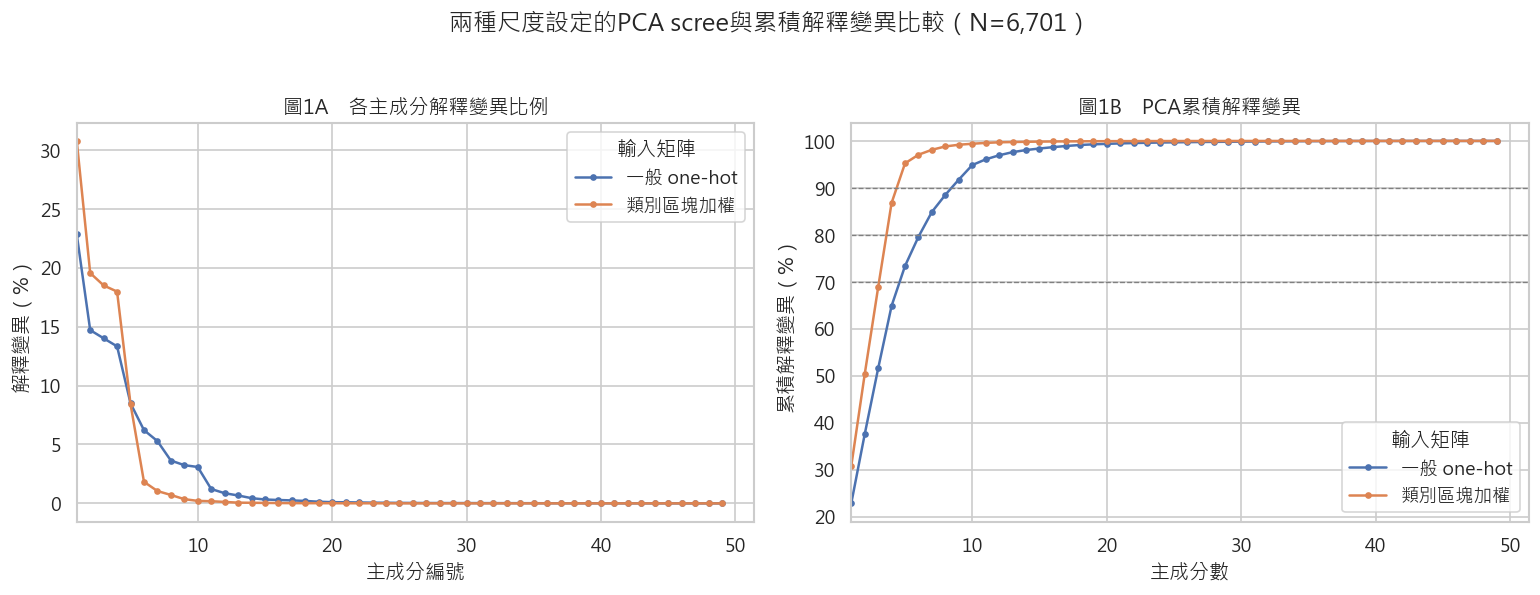

In [4]:
def readable_feature(name):
    replacements = {
        'z__speed_limit': '標準化速限', 'z__hour_sin': '事故小時 sin',
        'z__hour_cos': '事故小時 cos', 'z__month_sin': '事故月份 sin',
        'z__month_cos': '事故月份 cos', 'weather_code__': '天候代碼 ',
        'road_class_code__': '道路類別代碼 ', 'road_form_code__': '道路型態代碼 ',
        'crash_position_code__': '事故位置代碼 ',
    }
    for old, new in replacements.items():
        name = name.replace(old, new)
    return name

pca_models = {}
pca_scores_80 = {}
pca_threshold_rows = []
loading_rows = []
for variant, frame in matrices.items():
    X = frame.drop(columns='record_id').to_numpy(dtype=float)
    feature_names = frame.columns[1:].tolist()
    model = PCA(svd_solver='full')
    scores = model.fit_transform(X)
    cumulative = np.cumsum(model.explained_variance_ratio_)
    pca_models[variant] = model
    for threshold in [0.70, 0.80, 0.90]:
        n_components = int(np.searchsorted(cumulative, threshold) + 1)
        pca_threshold_rows.append({
            'matrix': variant, 'variance_threshold': threshold,
            'components_needed': n_components,
            'actual_cumulative_variance': cumulative[n_components - 1],
        })
    n80 = int(np.searchsorted(cumulative, 0.80) + 1)
    pca_scores_80[variant] = scores[:, :n80]
    for component_index in range(min(5, model.components_.shape[0])):
        component = model.components_[component_index]
        top_indices = np.argsort(np.abs(component))[::-1][:10]
        for rank, feature_index in enumerate(top_indices, start=1):
            loading_rows.append({
                'matrix': variant, 'principal_component': f'PC{component_index + 1}',
                'rank_by_absolute_loading': rank,
                'feature': feature_names[feature_index],
                'readable_feature': readable_feature(feature_names[feature_index]),
                'loading': component[feature_index],
                'absolute_loading': abs(component[feature_index]),
                'component_variance_ratio': model.explained_variance_ratio_[component_index],
            })

pca_thresholds = pd.DataFrame(pca_threshold_rows)
top_loadings = pd.DataFrame(loading_rows)
print('表4　PCA累積解釋變異門檻（N=6,701；各矩陣49個特徵）')
display(pca_thresholds)
print('表5　前五個主成分各自絕對 loading 最大的十個特徵')
display(top_loadings)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for variant, model in pca_models.items():
    component_numbers = np.arange(1, len(model.explained_variance_ratio_) + 1)
    axes[0].plot(component_numbers, model.explained_variance_ratio_ * 100, marker='o', ms=3, label=variant)
    axes[1].plot(component_numbers, np.cumsum(model.explained_variance_ratio_) * 100, marker='o', ms=3, label=variant)
axes[0].set(title='圖1A　各主成分解釋變異比例', xlabel='主成分編號', ylabel='解釋變異（%）')
axes[1].set(title='圖1B　PCA累積解釋變異', xlabel='主成分數', ylabel='累積解釋變異（%）')
for level in [70, 80, 90]:
    axes[1].axhline(level, color='grey', linestyle='--', linewidth=0.8)
for ax in axes:
    ax.legend(title='輸入矩陣')
    ax.set_xlim(left=1)
fig.suptitle('兩種尺度設定的PCA scree與累積解釋變異比較（N=6,701）', y=1.03)
fig.tight_layout()
fig.savefig(ASSET_DIR / 'pca_scree_comparison.png', bbox_inches='tight')
plt.show()
pca_thresholds.to_csv(ASSET_DIR / 'pca_thresholds.csv', index=False, encoding='utf-8-sig')
top_loadings.to_csv(ASSET_DIR / 'pca_top_loadings.csv', index=False, encoding='utf-8-sig')


圖1比較一般 one-hot 與類別區塊加權後，單一主成分及累積解釋變異的差異。PCA loading 的正負方向可整體翻轉，因此解讀時重點是同一主成分內的相對方向與絕對大小；表5僅列前五個主成分的主要特徵，不把高 loading 自動解讀成因果影響。


C:\Users\User\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:110: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] 系統找不到指定的檔案。
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\User\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 199, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\User\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\User\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\User\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
            

表6　K-means群數比較（全樣本 N=6,701；silhouette為固定抽樣3,000筆）


,matrix,k,pca_components_80pct,inertia,silhouette_sample_n,silhouette,calinski_harabasz,davies_bouldin,stability_ari_mean_10_seeds,stability_ari_min_10_seeds,stability_ari_max_10_seeds,smallest_cluster_n,largest_cluster_n,inertia_drop_pct_from_previous_k
0,一般 one-hot,2,7,32333.912893,3000,0.192675,1674.971532,1.957464,1.000000,1.000000,1.000000,2944,3757,NaN
1,一般 one-hot,3,7,28382.080188,3000,0.194911,1420.256619,1.763346,0.997977,0.991401,1.000000,1410,2769,12.221944
2,一般 one-hot,4,7,25137.496969,3000,0.189330,1357.025777,1.629893,0.941476,0.818997,1.000000,1126,2213,11.431802
3,一般 one-hot,5,7,22700.406989,3000,0.183495,1306.621552,1.506977,0.994614,0.978154,1.000000,1071,1664,9.695038
4,一般 one-hot,6,7,20727.144964,3000,0.196139,1272.084090,1.436332,0.982333,0.925802,1.000000,596,1600,8.692628
5,類別區塊加權,2,4,22561.125815,3000,0.250054,2380.990833,1.631433,0.948518,0.855206,1.000000,2944,3757,NaN
6,類別區塊加權,3,4,18658.967914,3000,0.253773,2139.627148,1.515238,0.577277,0.253309,1.000000,2063,2410,17.295936
7,類別區塊加權,4,4,15540.060589,3000,0.274874,2160.477849,1.281769,0.820787,0.603330,1.000000,1344,1956,16.715326
8,類別區塊加權,5,4,13272.306128,3000,0.280137,2182.961139,1.142403,0.817282,0.623526,0.975378,1005,1786,14.592958
9,類別區塊加權,6,4,11619.674520,3000,0.302951,2184.978889,1.181976,0.803410,0.560498,0.995334,602,1661,12.451729


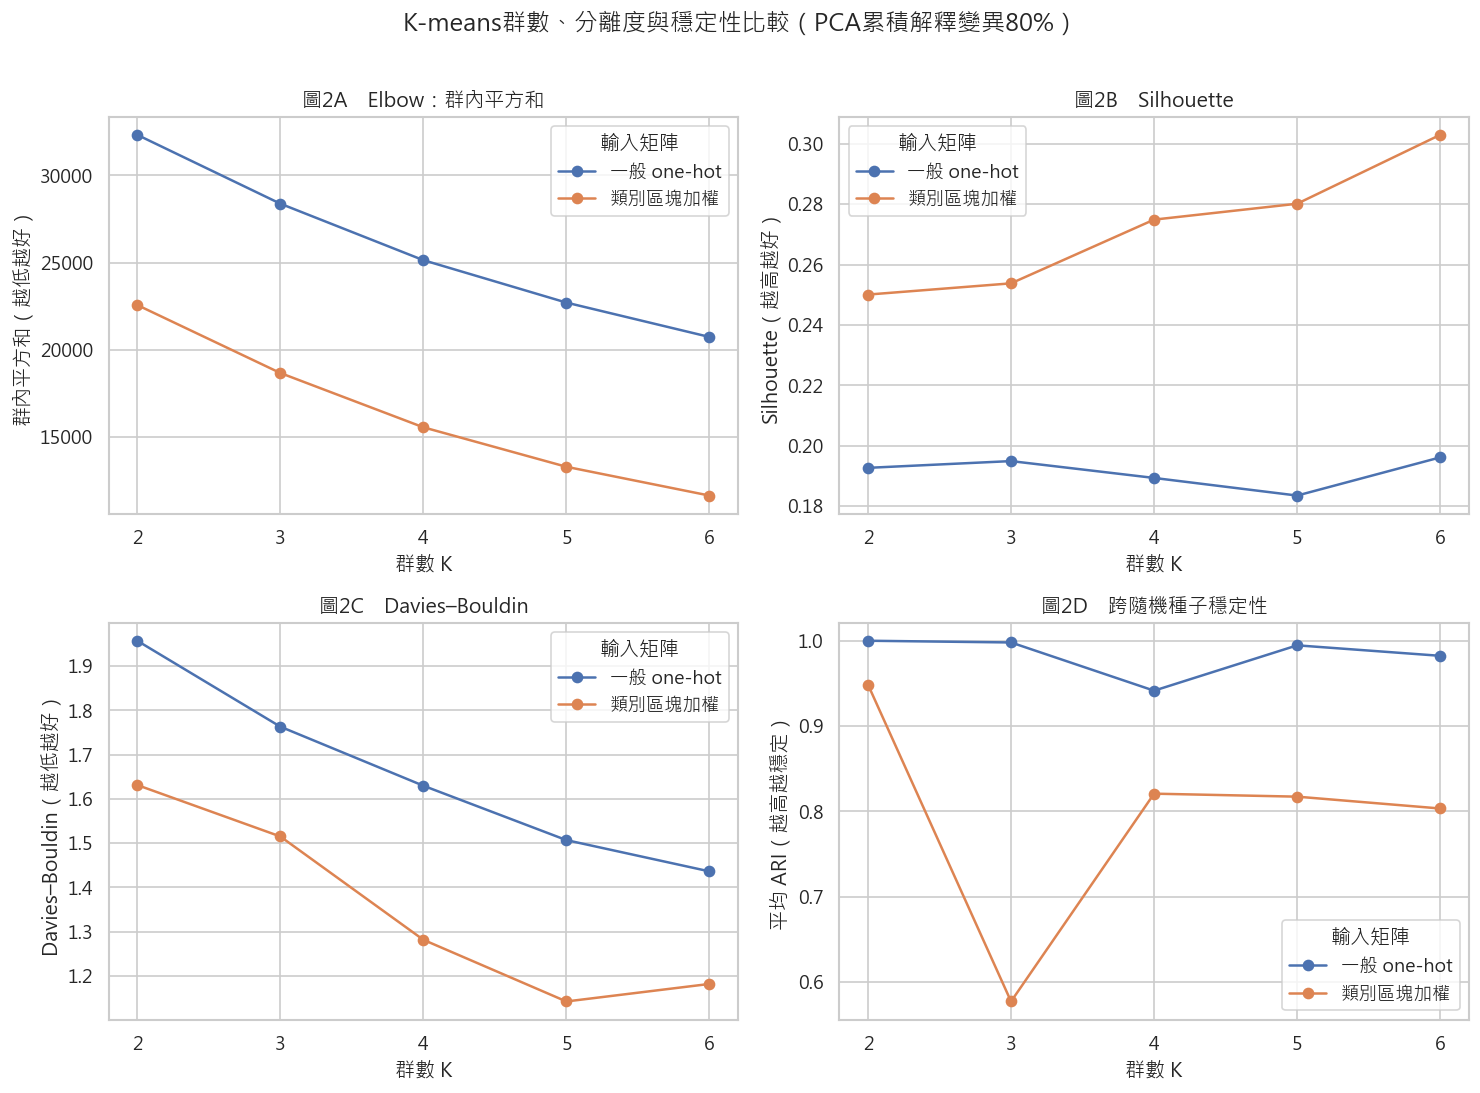

In [5]:
def mean_pairwise_ari(label_sets):
    aris = [adjusted_rand_score(a, b) for a, b in itertools.combinations(label_sets, 2)]
    return float(np.mean(aris)), float(np.min(aris)), float(np.max(aris))

kmeans_rows = []
kmeans_labels = {}
for variant, scores in pca_scores_80.items():
    for k in K_VALUES:
        main_model = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE, algorithm='lloyd')
        labels = main_model.fit_predict(scores)
        seed_labels = [
            KMeans(n_clusters=k, n_init=10, random_state=seed, algorithm='lloyd').fit_predict(scores)
            for seed in STABILITY_SEEDS
        ]
        ari_mean, ari_min, ari_max = mean_pairwise_ari(seed_labels)
        counts = pd.Series(labels).value_counts()
        kmeans_labels[(variant, k)] = labels
        kmeans_rows.append({
            'matrix': variant, 'k': k, 'pca_components_80pct': scores.shape[1],
            'inertia': main_model.inertia_,
            'silhouette_sample_n': min(SILHOUETTE_SAMPLE_SIZE, len(scores)),
            'silhouette': silhouette_score(
                scores, labels, sample_size=min(SILHOUETTE_SAMPLE_SIZE, len(scores)),
                random_state=RANDOM_STATE,
            ),
            'calinski_harabasz': calinski_harabasz_score(scores, labels),
            'davies_bouldin': davies_bouldin_score(scores, labels),
            'stability_ari_mean_10_seeds': ari_mean,
            'stability_ari_min_10_seeds': ari_min,
            'stability_ari_max_10_seeds': ari_max,
            'smallest_cluster_n': int(counts.min()),
            'largest_cluster_n': int(counts.max()),
        })

kmeans_metrics = pd.DataFrame(kmeans_rows).sort_values(['matrix', 'k']).reset_index(drop=True)
kmeans_metrics['inertia_drop_pct_from_previous_k'] = (
    kmeans_metrics.groupby('matrix')['inertia'].pct_change().mul(-100)
)
print('表6　K-means群數比較（全樣本 N=6,701；silhouette為固定抽樣3,000筆）')
display(kmeans_metrics)
kmeans_metrics.to_csv(ASSET_DIR / 'kmeans_metrics_k2_k6.csv', index=False, encoding='utf-8-sig')

fig, axes = plt.subplots(2, 2, figsize=(12.5, 9))
metric_specs = [
    ('inertia', '圖2A　Elbow：群內平方和', '群內平方和（越低越好）'),
    ('silhouette', '圖2B　Silhouette', 'Silhouette（越高越好）'),
    ('davies_bouldin', '圖2C　Davies–Bouldin', 'Davies–Bouldin（越低越好）'),
    ('stability_ari_mean_10_seeds', '圖2D　跨隨機種子穩定性', '平均 ARI（越高越穩定）'),
]
for ax, (metric, title, ylabel) in zip(axes.flat, metric_specs):
    for variant, group in kmeans_metrics.groupby('matrix'):
        ax.plot(group['k'], group[metric], marker='o', label=variant)
    ax.set(title=title, xlabel='群數 K', ylabel=ylabel, xticks=list(K_VALUES))
    ax.legend(title='輸入矩陣')
fig.suptitle('K-means群數、分離度與穩定性比較（PCA累積解釋變異80%）', y=1.01)
fig.tight_layout()
fig.savefig(ASSET_DIR / 'kmeans_metrics_comparison.png', bbox_inches='tight')
plt.show()


圖2不以單一指標決定群數：inertia必然隨K增加而下降；silhouette衡量群內緊密與群間分離；Davies–Bouldin越低越好；ARI則檢查不同初始化是否得到近似分群。若不同指標不一致，候選群數仍須配合群組大小、原始變數 profile 與可解釋性判斷。


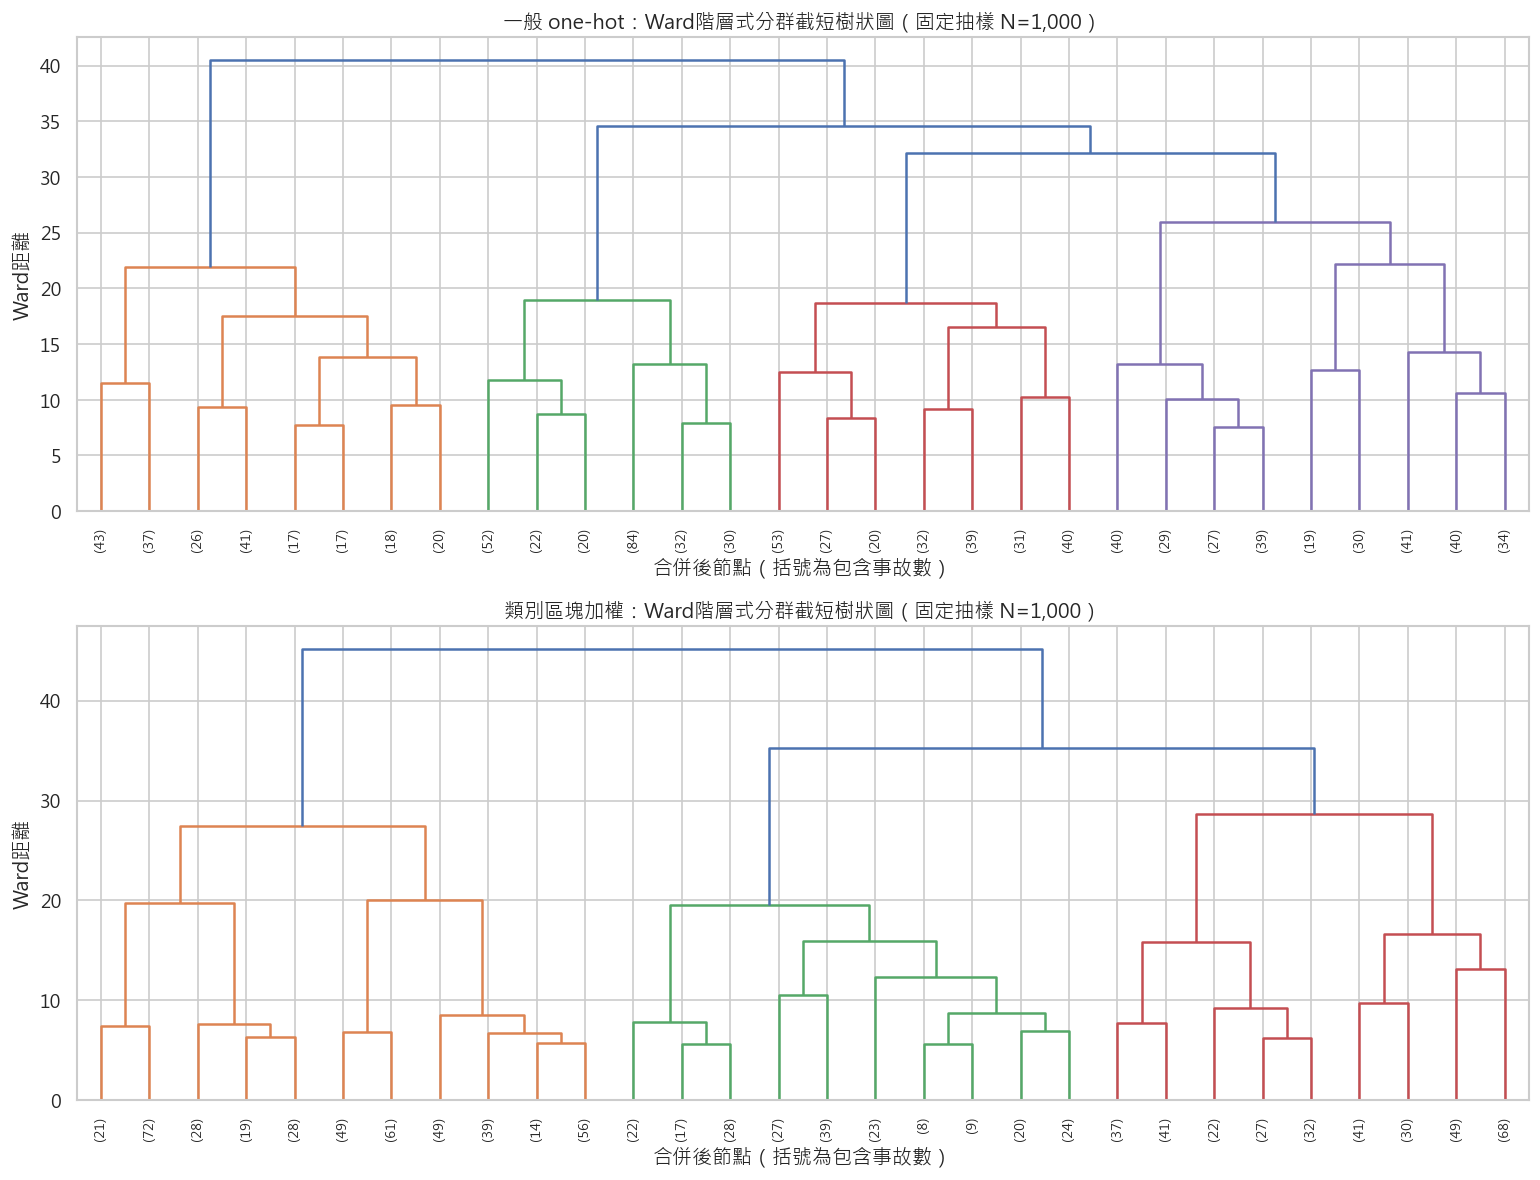

表7　Ward階層式分群固定抽樣群數比較（每矩陣 N=1,000）


,matrix,k,sample_n,silhouette,smallest_cluster_n,largest_cluster_n
0,一般 one-hot,2,1000,0.184373,219,781
1,一般 one-hot,3,1000,0.123625,219,541
2,一般 one-hot,4,1000,0.134757,219,299
3,一般 one-hot,5,1000,0.131235,135,242
4,一般 one-hot,6,1000,0.134251,49,242
5,類別區塊加權,2,1000,0.212950,436,564
6,類別區塊加權,3,1000,0.232070,217,436
7,類別區塊加權,4,1000,0.232862,159,436
8,類別區塊加權,5,1000,0.243319,159,268
9,類別區塊加權,6,1000,0.225891,110,217


In [6]:
rng = np.random.default_rng(RANDOM_STATE)
hierarchical_indices = np.sort(rng.choice(len(semantic), size=HIERARCHICAL_SAMPLE_SIZE, replace=False))
hierarchical_rows = []
linkages = {}
fig, axes = plt.subplots(2, 1, figsize=(13, 10))
for ax, (variant, scores) in zip(axes, pca_scores_80.items()):
    sample_scores = scores[hierarchical_indices]
    Z = linkage(sample_scores, method='ward', optimal_ordering=False)
    linkages[variant] = Z
    dendrogram(
        Z, truncate_mode='lastp', p=30, show_leaf_counts=True,
        leaf_rotation=90, leaf_font_size=8, ax=ax, color_threshold=None,
    )
    ax.set(
        title=f'{variant}：Ward階層式分群截短樹狀圖（固定抽樣 N=1,000）',
        xlabel='合併後節點（括號為包含事故數）', ylabel='Ward距離',
    )
    for k in K_VALUES:
        labels = fcluster(Z, t=k, criterion='maxclust')
        counts = pd.Series(labels).value_counts()
        hierarchical_rows.append({
            'matrix': variant, 'k': k, 'sample_n': HIERARCHICAL_SAMPLE_SIZE,
            'silhouette': silhouette_score(sample_scores, labels),
            'smallest_cluster_n': int(counts.min()),
            'largest_cluster_n': int(counts.max()),
        })
fig.tight_layout()
fig.savefig(ASSET_DIR / 'hierarchical_dendrograms.png', bbox_inches='tight')
plt.show()

hierarchical_metrics = pd.DataFrame(hierarchical_rows)
print('表7　Ward階層式分群固定抽樣群數比較（每矩陣 N=1,000）')
display(hierarchical_metrics)
hierarchical_metrics.to_csv(ASSET_DIR / 'hierarchical_sample_metrics.csv', index=False, encoding='utf-8-sig')


In [7]:
cross_matrix_agreement = pd.DataFrame([
    {
        'k': k,
        'adjusted_rand_index': adjusted_rand_score(
            kmeans_labels[('一般 one-hot', k)],
            kmeans_labels[('類別區塊加權', k)],
        ),
    }
    for k in K_VALUES
])
print('表8　相同K下兩種矩陣的K-means分群一致度（全樣本 N=6,701）')
display(cross_matrix_agreement)
cross_matrix_agreement.to_csv(ASSET_DIR / 'cross_matrix_agreement.csv', index=False, encoding='utf-8-sig')

candidate_rows = []
for variant, group in kmeans_metrics.groupby('matrix'):
    hierarchy_group = hierarchical_metrics[hierarchical_metrics['matrix'].eq(variant)]
    candidate_rows.append({
        'matrix': variant,
        'k_best_silhouette': int(group.loc[group['silhouette'].idxmax(), 'k']),
        'k_best_calinski_harabasz': int(group.loc[group['calinski_harabasz'].idxmax(), 'k']),
        'k_best_davies_bouldin': int(group.loc[group['davies_bouldin'].idxmin(), 'k']),
        'k_best_mean_stability_ari': int(group.loc[group['stability_ari_mean_10_seeds'].idxmax(), 'k']),
        'k_best_hierarchical_sample_silhouette': int(
            hierarchy_group.loc[hierarchy_group['silhouette'].idxmax(), 'k']
        ),
    })
candidate_summary = pd.DataFrame(candidate_rows)
print('表9　各評估指標支持的候選群數（探索性，不等於最終決定）')
display(candidate_summary)
candidate_summary.to_csv(ASSET_DIR / 'candidate_k_summary.csv', index=False, encoding='utf-8-sig')

asset_manifest = pd.DataFrame([
    {'asset': path.name, 'bytes': path.stat().st_size, 'sha256': sha256_file(path)}
    for path in sorted(ASSET_DIR.iterdir()) if path.is_file()
])
print('表10　本階段支援檔案清單')
display(asset_manifest)


表8　相同K下兩種矩陣的K-means分群一致度（全樣本 N=6,701）


,k,adjusted_rand_index
0,2,1.000000
1,3,0.315800
2,4,0.775370
3,5,0.842861
4,6,0.767710


表9　各評估指標支持的候選群數（探索性，不等於最終決定）


,matrix,k_best_silhouette,k_best_calinski_harabasz,k_best_davies_bouldin,k_best_mean_stability_ari,k_best_hierarchical_sample_silhouette
0,一般 one-hot,6,2,6,2,2
1,類別區塊加權,6,2,5,2,5


表10　本階段支援檔案清單


,asset,bytes,sha256
0,candidate_k_summary.csv,196,5a2989b275df391ce187f9390e3f6e650ce0454a2e0f17...
1,cross_matrix_agreement.csv,121,f45e5b401aa73c55d6910f78b37a0039a1743f8224d9c8...
2,hierarchical_dendrograms.png,91563,de1cfd920fa566cffd19517b96ed61e092868c8351989b...
3,hierarchical_sample_metrics.csv,597,79ad8ea81c5ffbd3c5da619756d05291ac3e3bbf0358a9...
4,kmeans_metrics_comparison.png,201020,f25d158b10c1a8ba4a057cff4e11727cfa87d41e268852...
5,kmeans_metrics_k2_k6.csv,1949,35196cb85af71cdb692aebd38970e4884a0ab1d2d53676...
6,pca_scree_comparison.png,107909,ad10c15a4006f57eb6d24d553fb51497afbc4cf67b5606...
7,pca_thresholds.csv,333,9d3a6971321ee84728c3d2ce373941e55eac79b187c139...
8,pca_top_loadings.csv,12012,eddf4e56a5239d7cf66e38ecbe15886962773cad6c9f17...


## 結果解讀與限制

一般 one-hot 規格在70%、80%、90%累積解釋變異門檻分別需要5、7、9個主成分；類別區塊加權規格分別需要4、4、5個。兩種規格的前四個主成分主要反映事故時間、月份與速限，一般矩陣的PC5才由道路型態代碼14與4、事故位置代碼9與1等類別特徵主導。這表示區塊加權雖降低多類別變數的機械性影響，也可能使80%門檻下的PCA幾乎只留下數值時間特徵。

一般矩陣的silhouette介於0.183至0.196，K=6最高（0.196），但K=2的跨種子平均ARI為1.000，且Calinski–Harabasz與Ward抽樣silhouette支持K=2。區塊加權矩陣的silhouette由K=2的0.250上升至K=6的0.303；Davies–Bouldin在K=5最低（1.142），Ward抽樣silhouette也在K=5最高（0.243），但Calinski–Harabasz與平均穩定性仍偏向K=2。這些silhouette整體只屬有限至中等分離，不能宣稱資料存在非常清楚的天然群組。

尺度敏感度方面，K=2在兩種矩陣下完全一致（ARI=1.000）；K=3的一致度很低（0.316），不宜作主要候選。K=4、K=5、K=6的一致度分別為0.775、0.843與0.768，K=5是較細緻方案中跨矩陣最一致者。綜合分離度、穩定性、Ward輔助與尺度敏感度，本階段建議下一步優先檢查K=5的原始變數profile，以K=2作穩定但粗略的基準，K=6作silhouette較高的敏感度規格；最終群數仍待profile與照明／傷亡比較後決定。

本分析是事故案件內的探索性分群，不是全市道路事故風險模型。群組差異不能解讀成照明或道路條件造成事故；PCA與K-means也都對編碼、尺度、主成分門檻及群數敏感。Silhouette使用固定抽樣3,000筆，Ward階層式分群使用固定抽樣1,000筆，均是計算與可讀性的折衷。最終群數仍須在下一階段檢查各群原始變數 profile、樣本大小、照明與傷亡比例及跨規格一致性。
